In [ ]:
from google.colab import files

uploaded = files.upload()

Saving ipl_match_metrics_new_rerun.csv to ipl_match_metrics_new_rerun.csv


========== EXPERIMENT 2 RESULTS ==========
Observations       : 2468
NRR Mean           : 0.0000
NRRR Mean          : -0.0000
NRR Std Dev        : 1.8327
NRRR Std Dev       : 0.5033
Pearson Correlation: 0.9366
P-value            : 0


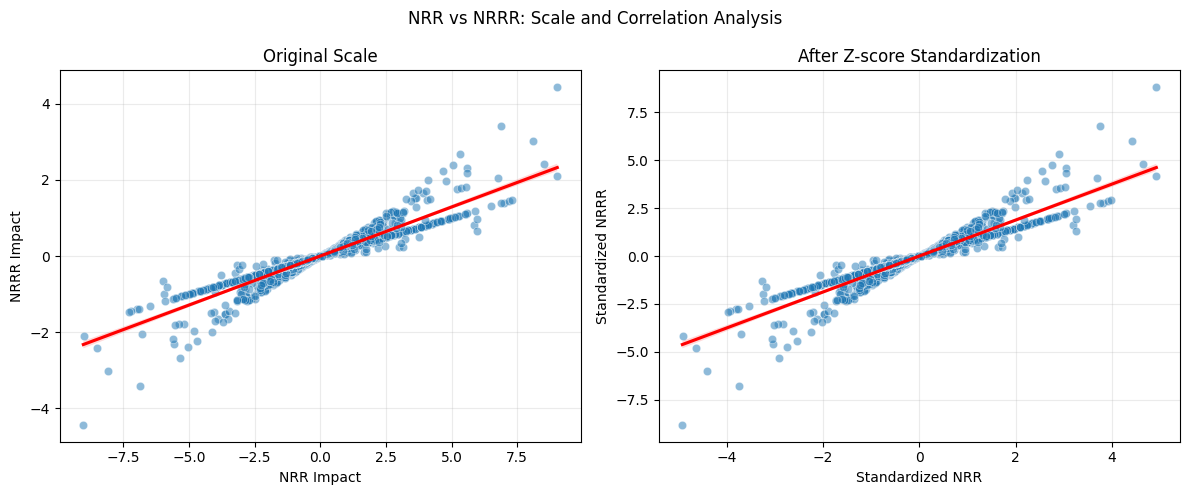

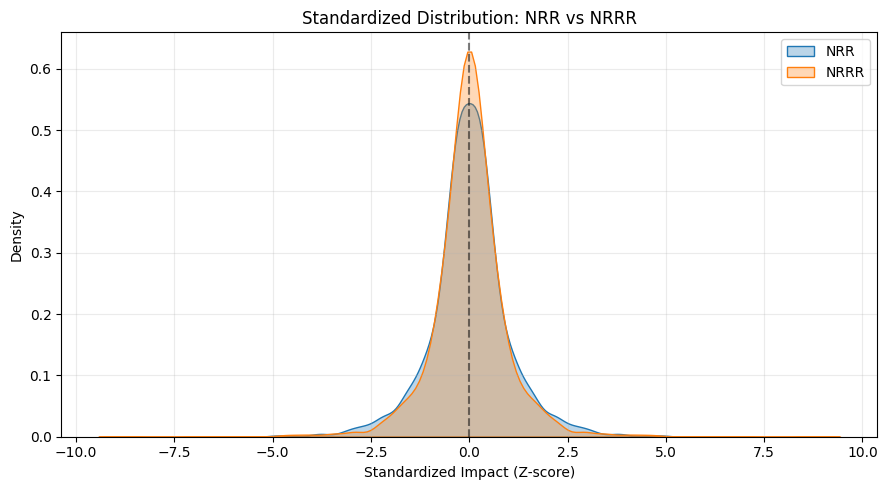


========== INTERPRETATION ==========
Very strong positive linear relationship.
The linear correlation is statistically significant.

Experiment 2 completed.


In [ ]:


# NRR vs NRRR

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

# Load dataset

df = pd.read_csv("ipl_match_metrics_new_rerun.csv")

columns = ["nrr1", "nrr2", "nrrr1", "nrrr2"]

for col in columns:
    df[col] = pd.to_numeric(df[col], errors="coerce")

df[columns] = df[columns].replace(
    [np.inf, -np.inf], np.nan
)

df = df.dropna(subset=columns).copy()


#Create paired observations

paired = pd.concat([
    df[["id", "nrr1", "nrrr1"]].rename(
        columns={"nrr1": "NRR", "nrrr1": "NRRR"}
    ),
    df[["id", "nrr2", "nrrr2"]].rename(
        columns={"nrr2": "NRR", "nrrr2": "NRRR"}
    )
], ignore_index=True)

#  Z-score standardization


paired["NRR_Z"] = stats.zscore(paired["NRR"])
paired["NRRR_Z"] = stats.zscore(paired["NRRR"])

#  Statistical analysis


pearson_r, p_value = stats.pearsonr(
    paired["NRR"],
    paired["NRRR"]
)

print("========== EXPERIMENT 2 RESULTS ==========")

print(f"Observations       : {len(paired)}")
print(f"NRR Mean           : {paired['NRR'].mean():.4f}")
print(f"NRRR Mean          : {paired['NRRR'].mean():.4f}")

print(f"NRR Std Dev        : {paired['NRR'].std():.4f}")
print(f"NRRR Std Dev       : {paired['NRRR'].std():.4f}")

print(f"Pearson Correlation: {pearson_r:.4f}")
print(f"P-value            : {p_value:.4g}")


# Original scale comparison


fig, axes = plt.subplots(1, 2, figsize=(12, 5))

sns.scatterplot(
    data=paired,
    x="NRR",
    y="NRRR",
    alpha=0.5,
    ax=axes[0]
)

sns.regplot(
    data=paired,
    x="NRR",
    y="NRRR",
    scatter=False,
    color="red",
    ax=axes[0]
)

axes[0].set_title("Original Scale")
axes[0].set_xlabel("NRR Impact")
axes[0].set_ylabel("NRRR Impact")

# Standardized comparison

sns.scatterplot(
    data=paired,
    x="NRR_Z",
    y="NRRR_Z",
    alpha=0.5,
    ax=axes[1]
)

sns.regplot(
    data=paired,
    x="NRR_Z",
    y="NRRR_Z",
    scatter=False,
    color="red",
    ax=axes[1]
)

axes[1].set_title("After Z-score Standardization")
axes[1].set_xlabel("Standardized NRR")
axes[1].set_ylabel("Standardized NRRR")

for ax in axes:
    ax.grid(alpha=0.25)

fig.suptitle("NRR vs NRRR: Scale and Correlation Analysis")
plt.tight_layout()
plt.show()


# Standardized distribution comparison

plt.figure(figsize=(9, 5))

sns.kdeplot(
    paired["NRR_Z"],
    label="NRR",
    fill=True,
    alpha=0.3
)

sns.kdeplot(
    paired["NRRR_Z"],
    label="NRRR",
    fill=True,
    alpha=0.3
)

plt.axvline(0, color="black", linestyle="--", alpha=0.5)

plt.title("Standardized Distribution: NRR vs NRRR")
plt.xlabel("Standardized Impact (Z-score)")
plt.ylabel("Density")
plt.legend()
plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()


# Interpretation


print("\n========== INTERPRETATION ==========")

if pearson_r >= 0.9:
    print("Very strong positive linear relationship.")
elif pearson_r >= 0.7:
    print("Strong positive linear relationship.")
elif pearson_r >= 0.4:
    print("Moderate positive linear relationship.")
else:
    print("Weak or limited positive linear relationship.")

if p_value < 0.05:
    print("The linear correlation is statistically significant.")
else:
    print("Insufficient evidence of a non-zero linear correlation.")





## Objective

The objective of this experiment is to investigate whether the difference in the distributions of NRR and NRRR is primarily due to numerical scaling or whether the two metrics capture different patterns of match performance.

## Mathematical Approach

We employ two statistical techniques:

**1. Z-score Standardization**

Both NRR and NRRR observations are standardized using:

\[
Z=\frac{X-\mu}{\sigma}
\]

This removes differences in mean and standard deviation, allowing us to compare the relative distribution patterns of the two metrics.

**2. Pearson Correlation Coefficient**

Pearson correlation measures the strength and direction of the linear relationship between corresponding NRR and NRRR match impacts.

\[
r=\frac{\operatorname{Cov}(X,Y)}{\sigma_X\sigma_Y}
\]

A high positive correlation indicates that both metrics tend to capture similar variations in match performance.

## My Hypothesis and Thoughts

A narrower distribution is potentially desirable because it may indicate greater stability and reduced sensitivity to individual match variations.

However, a reduction in standard deviation alone does not establish that NRRR is a superior metric. Such a reduction could simply result from a change in numerical scale.

Therefore, I investigate whether NRRR maintains a strong relationship with NRR after accounting for differences in scale.

If the standardized distributions exhibit similar patterns and Pearson correlation is high, this would suggest that NRRR retains much of the relative information contained in NRR while expressing it on a different numerical scale.

If the standardized distributions differ substantially, it may indicate that NRRR changes the way match performances are represented.

## Conclusion

This experiment aims to distinguish between a simple numerical rescaling and a meaningful change in the statistical behaviour of the metric.

The results will help determine whether the narrower distribution observed in NRRR represents a potentially useful property or merely a mathematical consequence of its construction.